# SynthHeart · 02 · Train TabDDPM and generate synthetic patients

Run this on the **AI Factory GPU**. A full run (20,000 iterations, 2,000 diffusion steps) takes **about 4–5 hours**, so:

1. **First run a smoke test**: leave `RUN_MODE = "smoke"` (~minutes) to prove the setup works end to end.
2. **Then the real run**: set `RUN_MODE = "full"`, and launch it **in the background** so it survives a closed browser tab:

```bash
cd <repo>/implementations/synthheart
nohup uv run jupyter nbconvert --to notebook --execute 02_train_tabddpm_and_generate.ipynb \
      --output 02_train_tabddpm_and_generate.executed.ipynb \
      --ExecutePreprocessor.timeout=-1 > logs/02_full_run.log 2>&1 &
tail -f logs/02_full_run.log          # watch progress; Ctrl+C stops watching, not training
```

**Inputs** (from notebook 01): `data/cardio/` (`cardio.csv` = train split, `cardio_domain.json`, `dataset_meta.json`)
**Outputs** (git-ignored, large): `runs/<RUN_MODE>/models/None_cardio_ckpt.pkl` (trained model) and `runs/<RUN_MODE>/synth_scale_*/...` (synthetic CSVs)
**Committed summary**: `results/02_generation_summary_<RUN_MODE>.json`

Adapted from the bootcamp's `implementations/tabular_data/single_table/training` and `synthesizing` notebooks (midst-toolkit `clava_training` / `clava_synthesizing`).

## 0 · Settings: the only cell you should need to edit

In [1]:
RUN_MODE = "smoke"        # "smoke" = quick end-to-end check   |   "full" = the real 4-5 h run

SAMPLE_SCALES = [1.0, 2.0]  # synthetic size as a multiple of the train split (41k rows): 1x and 2x for the dose test

DIFFUSION = {
    "full":  dict(iterations=20000, num_timesteps=2000, batch_size=4096),   # same as the bootcamp's single-table config
    "smoke": dict(iterations=200,   num_timesteps=100,  batch_size=1024),   # just proves the pipeline runs
}[RUN_MODE]

DIFFUSION_CONFIG = dict(
    d_layers=[512, 1024, 1024, 1024, 1024, 512],
    dropout=0.0,
    model_type="mlp",
    lr=0.0006,
    gaussian_loss_type="mse",
    weight_decay=1e-05,
    scheduler="cosine",
    data_split_ratios=[0.99, 0.005, 0.005],     # only the train portion is used by the pipeline
    merge_categoricals_into_numerical=False,    # False = true TabDDPM: categoricals get multinomial diffusion
    **DIFFUSION,
)
print(RUN_MODE, DIFFUSION_CONFIG)

smoke {'d_layers': [512, 1024, 1024, 1024, 1024, 512], 'dropout': 0.0, 'model_type': 'mlp', 'lr': 0.0006, 'gaussian_loss_type': 'mse', 'weight_decay': 1e-05, 'scheduler': 'cosine', 'data_split_ratios': [0.99, 0.005, 0.005], 'merge_categoricals_into_numerical': False, 'iterations': 200, 'num_timesteps': 100, 'batch_size': 1024}


## 1 · Setup and GPU check

In [2]:
import json
import pickle
import sys
import time
from logging import INFO
from pathlib import Path

import pandas as pd
import torch

here = Path.cwd().resolve()
project = next(p / "implementations" / "synthheart" for p in [here, *here.parents]
               if (p / "implementations" / "synthheart" / "synthheart_common.py").exists())
sys.path.insert(0, str(project))
import synthheart_common as sh

from midst_toolkit.common.config import (ClavaDDPMDiffusionConfig, ClavaDDPMMatchingConfig,
                                         ClavaDDPMSamplingConfig, GeneralConfig)
from midst_toolkit.common.logger import TOOLKIT_LOGGER, log
from midst_toolkit.common.random import set_all_random_seeds
from midst_toolkit.common.variables import DEVICE
from midst_toolkit.models.clavaddpm.data_loaders import load_tables
from midst_toolkit.models.clavaddpm.train import ClavaDDPMModelArtifacts, clava_training
from midst_toolkit.models.clavaddpm.synthesizer import clava_synthesizing

TOOLKIT_LOGGER.setLevel(INFO)
set_all_random_seeds(seed=sh.SEED)

RUN_DIR = sh.PROJECT / "runs" / RUN_MODE
(sh.PROJECT / "logs").mkdir(exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("device:", DEVICE, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))
elif RUN_MODE == "full":
    raise RuntimeError("RUN_MODE='full' needs a GPU. On CPU this would take days. Use the AI Factory GPU.")
print("data:", sh.DATA_DIR)
print("run dir:", RUN_DIR)

/home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


INFO :      Setting random seeds to 42.


device: cuda | cuda available: True
gpu: NVIDIA H200
data: /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/data/cardio
run dir: /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke


## 2 · Load the train split

`load_tables` reads `dataset_meta.json` and `cardio_domain.json`, then loads `cardio.csv` (the 60% train split only; holdout and test are never seen by the generator).

In [3]:
assert (sh.DATA_DIR / f"{sh.TABLE}.csv").exists(), "Run notebook 01 first to create data/cardio/"
tables, relation_order, _ = load_tables(sh.DATA_DIR)
assert relation_order == [(None, sh.TABLE)], relation_order
print(tables[sh.TABLE].data.shape)
tables[sh.TABLE].data.head()

INFO :      Training data ratio is 1, so the data will not be split into training and test sets.


INFO :      Train dataframe shape: (41135, 12)


INFO :      Total dataframe shape: (41135, 12)


INFO :      Numerical data shape: (41135, 5)


INFO :      Categorical data shape: (41135, 7)


(41135, 12)


,age,height,weight,ap_hi,ap_lo,gender,cholesterol,gluc,smoke,alco,active,cardio
0,56.0,156,64.0,140,90,0,1,0,0,0,1,1
1,60.1,183,110.0,130,80,1,2,2,0,0,1,1
2,51.8,168,70.0,120,80,1,0,0,0,0,1,1
3,57.7,167,64.0,140,90,0,2,0,0,0,0,1
4,51.4,170,70.0,110,70,0,1,0,0,0,1,0


## 3 · Train TabDDPM

Watch `GLoss` (numeric columns) and `MLoss` (categorical columns) fall in the log. The checkpoint is saved to `runs/<RUN_MODE>/models/None_cardio_ckpt.pkl`.

In [4]:
t0 = time.time()
tables, _ = clava_training(
    tables,
    relation_order,
    RUN_DIR,
    ClavaDDPMDiffusionConfig(**DIFFUSION_CONFIG),
    device=DEVICE,
)
train_minutes = (time.time() - t0) / 60
ckpt = RUN_DIR / "models" / f"None_{sh.TABLE}_ckpt.pkl"
with open(ckpt, "rb") as f:
    assert isinstance(pickle.load(f), ClavaDDPMModelArtifacts)
print(f"trained in {train_minutes:.1f} min -> {ckpt} ({ckpt.stat().st_size / 1e6:.1f} MB)")

INFO :      Training None -> cardio model from scratch


INFO :      No cache_dir provided. Will not attempt to load or save transformed dataset from/to cache


INFO :      No NaN processing policy specified.


INFO :      Model params: ModelParameters(diffusion_parameters=DiffusionParameters(layers_dimensions=[512, 1024, 1024, 1024, 1024, 512], dropout=0.0, input_dimension=0, output_dimension=0, embedding_dimension=0, n_blocks=0, block_dimension=0, hidden_dimension=0, dropout_first=0, dropout_second=0), input_dimension=np.int64(21), num_classes=0, is_target_conditioned=<IsTargetConditioned.NONE: 'none'>)


INFO :      Getting model: mlp


INFO :      Creating /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke/models. Saving None -> cardio model to /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke/models/None_cardio_ckpt.pkl


trained in 0.1 min -> /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke/models/None_cardio_ckpt.pkl (21.3 MB)


## 4 · Generate synthetic patients

One sampling run per `SAMPLE_SCALES` value. `sample_scale=1.0` gives as many rows as the train split.

In [5]:
with open(ckpt, "rb") as f:
    models = {relation_order[0]: pickle.load(f)}

synth_paths, sample_minutes = {}, {}
for scale in SAMPLE_SCALES:
    exp = f"synth_scale_{scale:g}"
    t0 = time.time()
    clava_synthesizing(
        tables,
        relation_order,
        RUN_DIR,
        models,
        GeneralConfig(data_dir=sh.DATA_DIR, test_data_dir=sh.DATA_DIR, exp_name=exp,
                      workspace_dir=RUN_DIR, sample_prefix=""),
        ClavaDDPMSamplingConfig(batch_size=20000, classifier_scale=1.0),
        ClavaDDPMMatchingConfig(num_matching_clusters=1, matching_batch_size=1000,
                                unique_matching=True, no_matching=False),
        sample_scale=scale,
    )
    sample_minutes[exp] = (time.time() - t0) / 60
    synth_paths[exp] = RUN_DIR / exp / sh.TABLE / "_final" / f"{sh.TABLE}_synthetic.csv"
    print(f"{exp}: {sample_minutes[exp]:.1f} min -> {synth_paths[exp]}")

INFO :      Generating None -> cardio


INFO :      Sample size: 41135


INFO :      Generating None -> cardio


INFO :      Sample size: 82270


synth_scale_1: 0.1 min -> /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke/synth_scale_1/cardio/_final/cardio_synthetic.csv


synth_scale_2: 0.1 min -> /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/runs/smoke/synth_scale_2/cardio/_final/cardio_synthetic.csv


## 5 · Round and filter the synthetic patients

Diffusion outputs continuous numbers (e.g. `cholesterol = 1.0000003`, `height = 167.6`). We snap them to the real data's types, then apply **the same medical-range rules** used to clean the real data in notebook 01.

In [6]:
real_train = pd.read_csv(sh.DATA_DIR / f"{sh.TABLE}.csv")
filtered, filter_report = {}, {}
for exp, path in synth_paths.items():
    raw_synth = pd.read_csv(path)
    synth = sh.round_synthetic(raw_synth)
    kept, fails = sh.apply_rules(synth)
    out = path.with_name(f"{sh.TABLE}_synthetic_filtered.csv")
    kept.to_csv(out, index=False)
    filtered[exp] = kept
    filter_report[exp] = {"generated": len(synth), "kept": len(kept), "pass_rate": round(len(kept) / len(synth), 4),
                          "rules_failed": {k: int(v) for k, v in fails[fails > 0].items()}}
    print(f"{exp}: kept {len(kept):,}/{len(synth):,} ({len(kept) / len(synth):.1%}) -> {out.name}")
    if (fails > 0).any():
        print("   failures:", filter_report[exp]["rules_failed"])

synth_scale_1: kept 30,716/41,135 (74.7%) -> cardio_synthetic_filtered.csv
   failures: {'ap_hi <= ap_lo': 10419}


synth_scale_2: kept 61,510/82,270 (74.8%) -> cardio_synthetic_filtered.csv
   failures: {'ap_hi <= ap_lo': 20760}


## 6 · First look: real vs synthetic

A quick eyeball check. The full scorecard (fidelity, utility, privacy) is notebook 03.

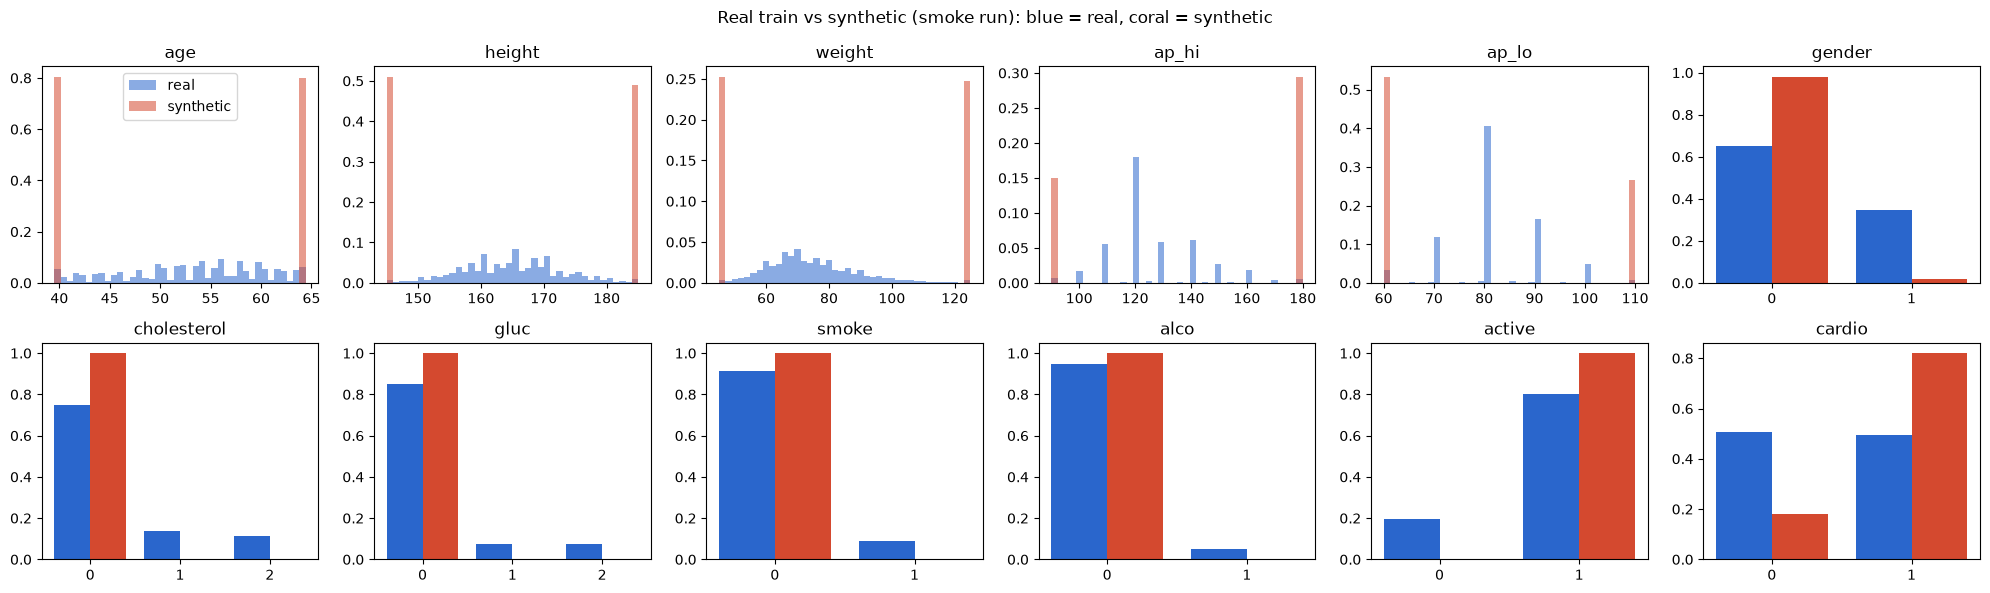

means (real vs synthetic):
             age  height  weight   ap_hi  ap_lo  gender  cholesterol  gluc  smoke  alco  active  cardio
real       53.32  164.41   74.12  126.72  81.34    0.35         0.36  0.23   0.09  0.05     0.8    0.49
synthetic  47.18  163.27  116.51  186.14  79.96    0.02         0.00  0.00   0.00  0.00     1.0    0.82


In [7]:
import matplotlib.pyplot as plt

synth = filtered[f"synth_scale_{SAMPLE_SCALES[0]:g}"]
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for ax, col in zip(axes.flat, sh.ALL_COLS):
    if col in sh.NUM_COLS:
        lo, hi = real_train[col].quantile([0.005, 0.995])
        bins = 40
        ax.hist(real_train[col].clip(lo, hi), bins=bins, alpha=0.55, density=True, label="real", color="#2a66cc")
        ax.hist(synth[col].clip(lo, hi), bins=bins, alpha=0.55, density=True, label="synthetic", color="#d4492f")
    else:
        r = real_train[col].value_counts(normalize=True).sort_index()
        s = synth[col].value_counts(normalize=True).reindex(r.index, fill_value=0)
        x = range(len(r))
        ax.bar([i - 0.2 for i in x], r.values, 0.4, label="real", color="#2a66cc")
        ax.bar([i + 0.2 for i in x], s.values, 0.4, label="synthetic", color="#d4492f")
        ax.set_xticks(list(x)); ax.set_xticklabels(r.index)
    ax.set_title(col)
axes.flat[0].legend()
fig.suptitle(f"Real train vs synthetic ({RUN_MODE} run): blue = real, coral = synthetic")
plt.tight_layout(); plt.show()

print("means (real vs synthetic):")
print(pd.DataFrame({"real": real_train.mean(), "synthetic": synth.mean()}).round(2).T.to_string())

## 7 · Quick sanity check: train on synthetic, test on real

One XGBoost model trained **only on synthetic patients**, scored on the **locked real test set**, against the real baseline from notebook 01. (A smoke run will score badly; that's expected.)

In [8]:
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

test = pd.read_csv(sh.DATA_DIR / f"{sh.TABLE}_test.csv")
X_te, y_te = sh.xy(test)
baseline_auc = json.loads((sh.RESULTS_DIR / "baseline_metrics.json").read_text())["trtr_baseline"]["xgboost"]["test_auc"]

tstr = {}
for exp, df in filtered.items():
    X_s, y_s = sh.xy(df)
    if len(set(y_s)) < 2:
        print(f"{exp}: only one class generated, skipping"); continue
    m = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                      eval_metric="logloss", random_state=sh.SEED, n_jobs=-1).fit(X_s, y_s)
    tstr[exp] = round(float(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])), 4)
    print(f"{exp}: TSTR AUC {tstr[exp]:.4f} | real baseline (TRTR) {baseline_auc:.4f} | gap {baseline_auc - tstr[exp]:+.4f}")

synth_scale_1: TSTR AUC 0.3552 | real baseline (TRTR) 0.8014 | gap +0.4462


synth_scale_2: TSTR AUC 0.5612 | real baseline (TRTR) 0.8014 | gap +0.2402


## 8 · Save the run summary (committed)

In [9]:
summary = {
    "run_mode": RUN_MODE,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "diffusion_config": DIFFUSION_CONFIG,
    "train_rows": int(len(real_train)),
    "train_minutes": round(train_minutes, 1),
    "sample_minutes": {k: round(v, 1) for k, v in sample_minutes.items()},
    "filter": filter_report,
    "tstr_auc_quick": tstr,
    "trtr_baseline_auc": baseline_auc,
}
sh.RESULTS_DIR.mkdir(exist_ok=True)
out = sh.RESULTS_DIR / f"02_generation_summary_{RUN_MODE}.json"
out.write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

{
  "run_mode": "smoke",
  "device": "cuda",
  "gpu": "NVIDIA H200",
  "diffusion_config": {
    "d_layers": [
      512,
      1024,
      1024,
      1024,
      1024,
      512
    ],
    "dropout": 0.0,
    "model_type": "mlp",
    "lr": 0.0006,
    "gaussian_loss_type": "mse",
    "weight_decay": 1e-05,
    "scheduler": "cosine",
    "data_split_ratios": [
      0.99,
      0.005,
      0.005
    ],
    "merge_categoricals_into_numerical": false,
    "iterations": 200,
    "num_timesteps": 100,
    "batch_size": 1024
  },
  "train_rows": 41135,
  "train_minutes": 0.1,
  "sample_minutes": {
    "synth_scale_1": 0.1,
    "synth_scale_2": 0.1
  },
  "filter": {
    "synth_scale_1": {
      "generated": 41135,
      "kept": 30716,
      "pass_rate": 0.7467,
      "rules_failed": {
        "ap_hi <= ap_lo": 10419
      }
    },
    "synth_scale_2": {
      "generated": 82270,
      "kept": 61510,
      "pass_rate": 0.7477,
      "rules_failed": {
        "ap_hi <= ap_lo": 20760
      }